In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar `creditsight` sin instalarlo: el código vive en ejemplo/src
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))


# 04 · Feature engineering — cada idea es una hipótesis que se mide

Crear variables nuevas es la parte más "creativa" del trabajo y por eso la más peligrosa: es fácil
añadir columnas que *suenan bien* y no aportan nada, y cada columna extra es complejidad que después
hay que calcular, validar y pedirle al usuario en la app.

Regla de esta etapa: **una idea entra al modelo solo si mejora la métrica de negocio por más que el
ruido de la validación**. Todo se compara con la misma validación cruzada por cliente.

| Idea | Por qué podría ayudar |
|---|---|
| **Razones financieras** (deuda/ingreso, cuota/sueldo, ahorro/sueldo, tipos de préstamo) | Un 1.000 de deuda pesa distinto con 20.000 que con 150.000 de ingreso |
| **Historial del mes anterior** (valor previo y promedio de meses pasados) | En un panel, lo que pasó antes suele predecir lo que pasa ahora |
| **`Credit_Mix`** | Muy asociada al objetivo en el EDA; ¿aporta o es redundante? |

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lightgbm import LGBMClassifier

from creditsight.config import PROCESSED_DIR, REPORTS_DIR, TARGET
from creditsight.data.split import group_cv
from creditsight.features.engineering import NUMERIC_ENGINEERED, add_features, feature_columns
from creditsight.models.train import build_pipeline, encode_target, evaluate

train = joblib.load(PROCESSED_DIR / "train.joblib").sort_values(["Customer_ID", "month_idx"]).reset_index(drop=True)
print(f"entrenamiento: {len(train):,} filas, {train.Customer_ID.nunique():,} clientes  (la prueba sigue cerrada)")

entrenamiento: 80,000 filas, 10,000 clientes  (la prueba sigue cerrada)


## Qué hacen las variables nuevas

Las razones se calculan con columnas del **mismo mes** (`add_features`), con división segura
(denominador cero → vacío, nunca infinito; hay una prueba para eso). Vemos si al menos *separan* las
clases a simple vista:

In [3]:
sample = add_features(train)
profile = sample.groupby(TARGET)[["debt_to_income", "emi_to_salary", "invested_to_salary", "balance_to_salary", "n_loan_types"]].median()
profile.loc[["Poor", "Standard", "Good"]].round(3)

,debt_to_income,emi_to_salary,invested_to_salary,balance_to_salary,n_loan_types
Credit_Score,,,,,
Poor,0.063,0.035,0.049,0.125,3.0
Standard,0.022,0.023,0.044,0.116,2.0
Good,0.012,0.017,0.041,0.108,2.0


Se ve diferencia, sobre todo en `debt_to_income`. Pero **ver diferencia no es lo mismo que mejorar el
modelo**: un árbol puede estar ya reconstruyendo esa razón con las columnas originales. La única forma
de saberlo es medir.

## El historial del mes anterior

Para cada cliente y mes, el valor del mes previo y el promedio de **meses anteriores** (nunca el
propio mes ni los futuros: eso sería fuga). El primer mes de cada cliente queda vacío, y el
pipeline ya sabe imputarlo.

In [4]:
HISTORY = ["Delay_from_due_date", "Num_of_Delayed_Payment", "Outstanding_Debt",
           "Credit_Utilization_Ratio", "Num_Credit_Inquiries", "Changed_Credit_Limit"]
by_customer = train.groupby("Customer_ID")
for col in HISTORY:
    train[f"prev_{col}"] = by_customer[col].shift(1)
    train[f"past_mean_{col}"] = by_customer[col].transform(lambda s: s.shift(1).expanding().mean())
history_cols = [f"prev_{c}" for c in HISTORY] + [f"past_mean_{c}" for c in HISTORY]

# Comprobación anti-fuga: en el primer mes de cada cliente no puede haber historial
first_month = train["month_idx"] == 0
assert train.loc[first_month, history_cols].isna().all().all()
print(f"{len(history_cols)} columnas de historial; vacías en el mes 0 (correcto): {train.loc[first_month, history_cols].isna().all().all()}")

12 columnas de historial; vacías en el mes 0 (correcto): True


## El experimento

Mismo modelo (LightGBM con parámetros fijos), misma validación (5 pliegues, **por cliente**), y solo
cambia el conjunto de variables. Medimos el costo esperado con la regla de decisión de negocio, y
también la calidad de las probabilidades (*log loss*), porque el costo puede ocultar mejoras que
aparecen en las probabilidades.

In [5]:
X, y = train.drop(columns=[TARGET]), encode_target(train[TARGET])
cv = group_cv(5)

variants = {
    "base, sin Credit_Mix":              dict(use_credit_mix=False),
    "base, con Credit_Mix (referencia)": dict(use_credit_mix=True),
    "+ razones financieras":             dict(use_credit_mix=True, use_engineered=True),
    "+ historial del mes anterior":      dict(use_credit_mix=True, extra_numeric=history_cols),
    "+ razones + historial":             dict(use_credit_mix=True, use_engineered=True, extra_numeric=history_cols),
}
rows = {}
for name, options in variants.items():
    model = LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1)
    rows[name] = evaluate(build_pipeline(model, scale=False, **options), X, y, cv)
    print(f"{name:36s} costo = {rows[name]['cost_mean']:.4f} ± {rows[name]['cost_std']:.4f}")
results = pd.DataFrame(rows).T

base, sin Credit_Mix                 costo = 0.4955 ± 0.0086


base, con Credit_Mix (referencia)    costo = 0.4894 ± 0.0075


+ razones financieras                costo = 0.4896 ± 0.0069


+ historial del mes anterior         costo = 0.4842 ± 0.0081


+ razones + historial                costo = 0.4834 ± 0.0088


In [6]:
ref = "base, con Credit_Mix (referencia)"
table = pd.DataFrame({
    "costo": results["cost_mean"],
    "± entre pliegues": results["cost_std"],
    "log loss": results["log_loss_mean"],
    "F1 macro": results["macro_f1_mean"],
    "recall Poor": results["recall_poor_mean"],
    "mejora de costo vs. referencia": results.loc[ref, "cost_mean"] - results["cost_mean"],
})
table["mejora / ruido"] = table["mejora de costo vs. referencia"] / results["cost_std"]
table.to_csv(REPORTS_DIR / "04_features_tabla.csv")
table.round(4)

,costo,± entre pliegues,log loss,F1 macro,recall Poor,mejora de costo vs. referencia,mejora / ruido
"base, sin Credit_Mix",0.4955,0.0086,0.6953,0.5397,0.7954,-0.0060,-0.6986
"base, con Credit_Mix (referencia)",0.4894,0.0075,0.6686,0.5442,0.8075,0.0000,0.0000
+ razones financieras,0.4896,0.0069,0.6671,0.5463,0.8063,-0.0001,-0.0163
+ historial del mes anterior,0.4842,0.0081,0.6571,0.5459,0.8081,0.0052,0.6426
+ razones + historial,0.4834,0.0088,0.6549,0.5489,0.8078,0.0061,0.6862


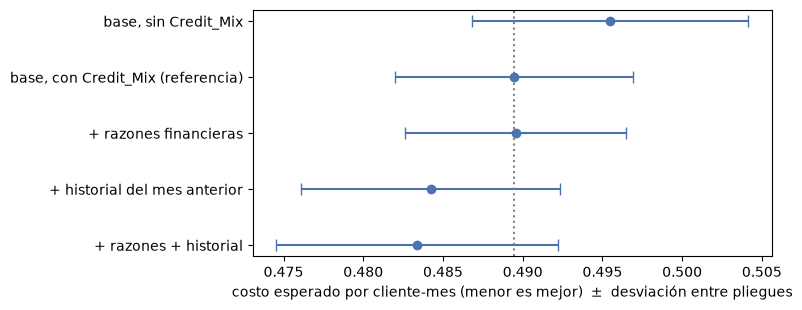

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.errorbar(results["cost_mean"], range(len(results)), xerr=results["cost_std"], fmt="o", color="#4c72b0", capsize=4)
ax.set_yticks(range(len(results))); ax.set_yticklabels(results.index)
ax.invert_yaxis(); ax.set_xlabel("costo esperado por cliente-mes (menor es mejor)  ±  desviación entre pliegues")
ax.axvline(results.loc[ref, "cost_mean"], color="grey", linestyle=":")
plt.tight_layout(); plt.show()

## Cómo leer la tabla

La columna clave es **mejora / ruido**: cuánto baja el costo comparado con lo que varía entre
pliegues. Una mejora menor que ~1 está dentro del ruido: con otra partición podría desaparecer.

**Lo que muestran los números:**

- **Las razones financieras no aportan.** La mejora de costo es una fracción del ruido. Un modelo de
  árboles ya puede reconstruir esas razones con las columnas originales. (En una prueba aparte con
  regresión logística, donde sí podrían ayudar, el resultado fue igual: no aportan.)
- **El historial del mes anterior tampoco aporta de forma convincente** en costo, y sí un poco en
  probabilidades. No justifica pedirle al usuario datos del mes pasado en la app.
- **`Credit_Mix` sí aporta, sobre todo a la calidad de las probabilidades** (el log loss mejora
  varias veces el ruido); en costo la mejora es pequeña. Pero ayuda en cada métrica.

## Decisión

| Idea | Decisión | Motivo |
|---|---|---|
| Razones financieras | **Descartar** | Sin mejora medible; menos columnas, menos riesgo |
| Historial del mes anterior | **Descartar** | Mejora marginal; complica la app y la inferencia |
| `Credit_Mix` | **Conservar, con una condición** | Mejora las probabilidades; solo es válida si **se conoce en el momento de decidir** |

> **La condición sobre `Credit_Mix` es un supuesto de negocio, no un resultado técnico.** Si en
> producción ese dato llegara *después* de calificar al cliente, usarlo sería una fuga. Queda escrito
> en la ficha del modelo y en el reporte, y la app permite dejarlo como "desconocido".

## Lo más importante de esta etapa

Se probaron tres ideas razonables y **dos no sirvieron**. Eso no es un fracaso: es información.
La mejora grande del proyecto vino de **entender y limpiar los datos** (etapas 2 y 3), no de
inventar columnas. Un modelo con menos variables es más fácil de explicar, de desplegar y de
mantener.

El código de las variables descartadas se conserva (`add_features`, con una opción para activarlas) porque
documenta la prueba; el pipeline final las deja apagadas.

**Siguiente:** `05_torneo.ipynb`, la comparación de modelos.